# 01 — Entendimento do dataset e qualidade dos dados

## Introdução

Este notebook inicia a análise do dataset **Video Game Sales with Ratings**
(VGChartz + Metacritic), com **16.719 registros**.

Aqui fazemos **somente o que é mineração**: carregar, entender, verificar a qualidade
e preparar os atributos. A LLM entra apenas no notebook 03, interpretando resultados
já prontos.

### Pergunta inicial

> **Quais jogos apresentam perfis semelhantes de vendas e avaliação, e quais se afastam do padrão do mercado?**

Essa pergunta orienta todas as decisões seguintes: quais atributos usar, quais
transformações aplicar e o que vale a pena investigar.


## 0. Configuração do ambiente

Usamos um kernel dedicado (`Python (Mineracao LLM)`). Os caminhos são resolvidos a partir
da raiz do projeto, para o notebook funcionar independente de onde for aberto.

**O que este código faz, passo a passo**
- Importa as bibliotecas: `sys`/`warnings` (sistema), `Path` (caminhos), `numpy`, `pandas`, `matplotlib` e `seaborn`.
- `warnings.filterwarnings("ignore")` silencia avisos que não impedem a execução.
- `sns.set_theme(...)` define apenas o visual dos gráficos.
- `pd.set_option(...)` faz o pandas exibir mais colunas sem cortar.
- **Caminho:** `RAIZ` sobe um nível se o notebook estiver na pasta `notebooks/`; caso contrário, usa a pasta atual. Assim o código funciona de qualquer lugar.
- O `print` confirma versões e a raiz.

**Não mexe nos dados** — é só preparação do ambiente.

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# raiz do projeto = pasta acima de notebooks/
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("Raiz do projeto:", RAIZ)


Python: 3.13.13
pandas: 3.0.5
Raiz do projeto: /home/ivan/Ivan2.0/6°DSM/Mineracao/Porjeto_final


## 1. Carregar o dataset

Cada **linha** representa um jogo em uma **plataforma** (o mesmo jogo pode aparecer em
plataformas diferentes). As vendas estão em **milhões de unidades**.

**O que este código faz**
- Monta o caminho do arquivo bruto: `data/raw/Video_Games.csv`.
- `pd.read_csv(..., low_memory=False)` lê o CSV inteiro de uma vez, evitando que o pandas infira tipos diferentes em pedaços diferentes.
- `df.shape` mostra **16.719 linhas × 16 colunas**.
- `df.head()` exibe as 5 primeiras linhas para conferência.

**Entra:** o CSV bruto.
**Sai:** o DataFrame `df`, com todas as 16 colunas e as 16.719 linhas. **Nada é excluído ainda.**

In [2]:
caminho = RAIZ / "data" / "raw" / "Video_Games.csv"
df = pd.read_csv(caminho, low_memory=False)
print(f"Linhas: {df.shape[0]:,} | Colunas: {df.shape[1]}")
df.head()


Linhas: 16,719 | Colunas: 16


,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN


### Dicionário dos atributos

| Coluna | Significado |
|---|---|
| `Name` | Nome do jogo |
| `Platform` | Plataforma (PS4, X360, Wii...) |
| `Year_of_Release` | Ano de lançamento |
| `Genre` | Gênero |
| `Publisher` / `Developer` | Publicadora / desenvolvedora |
| `NA_Sales`, `EU_Sales`, `JP_Sales`, `Other_Sales` | Vendas por região (milhões) |
| `Global_Sales` | Vendas globais (milhões) |
| `Critic_Score` | Nota da crítica Metacritic (0–100) |
| `Critic_Count` | Nº de críticas |
| `User_Score` | Nota dos usuários (0–10) |
| `User_Count` | Nº de avaliações de usuários |
| `Rating` | Classificação indicativa ESRB |

**Não há dados pessoais** — são informações agregadas de produtos.


## 2. Tipos e qualidade: os dados vêm como texto

O CSV original traz várias colunas numéricas como `object` (texto), e `User_Score`
contém o valor `"tbd"` (*to be determined*). Isso precisa ser tratado antes de qualquer cálculo.

**O que este código faz**
- `df.dtypes` lista o tipo de cada coluna. O esperado é ver várias colunas numéricas marcadas como `object` (texto).
- A segunda linha conta quantas vezes `User_Score` vale `"tbd"` → **2.425**.
- `.astype(str).str.strip().str.lower()` normaliza antes de comparar, evitando erro por espaço ou maiúscula.

**Por que isso importa:** se um número está armazenado como texto, somas e médias falham ou ignoram a linha silenciosamente.
**Nada é alterado aqui** — é apenas diagnóstico.

In [3]:
print("Tipos originais:")
print(df.dtypes.to_string())
print("\nValores 'tbd' em User_Score:",
      (df["User_Score"].astype(str).str.strip().str.lower() == "tbd").sum())


Tipos originais:
Name                   str
Platform               str
Year_of_Release    float64
Genre                  str
Publisher              str
NA_Sales           float64
EU_Sales           float64
JP_Sales           float64
Other_Sales        float64
Global_Sales       float64
Critic_Score       float64
Critic_Count       float64
User_Score             str
User_Count         float64
Developer              str
Rating                 str

Valores 'tbd' em User_Score: 2425


### Conversão para numérico

Usamos `errors="coerce"`: o que não for número vira `NaN` — assim não perdemos a linha,
só marcamos o valor como ausente.

**O que este código faz, linha a linha**
- Define `num_cols` com as **10 colunas que deveriam ser numéricas**:
  `Year_of_Release`, `NA_Sales`, `EU_Sales`, `JP_Sales`, `Other_Sales`, `Global_Sales`,
  `Critic_Score`, `Critic_Count`, `User_Score` e `User_Count`.
- **Ficam de fora, de propósito:** `Name`, `Platform`, `Genre`, `Publisher`, `Developer`
  e `Rating` — são categorias ou identificação, não valores numéricos.
- `pd.to_numeric(..., errors="coerce")` converte cada coluna; o que não for número vira `NaN`.
  Assim `"tbd"` e células vazias **não derrubam a execução** e não apagam o jogo.
- `astype("Int64")` transforma o ano em inteiro que aceita valor ausente.
- `describe().T` mostra contagem, média, desvio, mínimo e máximo para conferência de faixas.

**Entra:** `df` com números em texto.
**Sai:** o mesmo `df`, com as mesmas **16.719 linhas**, agora com as 10 colunas em formato numérico.

In [4]:
num_cols = ["Year_of_Release", "NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales",
            "Global_Sales", "Critic_Score", "Critic_Count", "User_Score", "User_Count"]
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df["Year_of_Release"] = df["Year_of_Release"].astype("Int64")
print(df[num_cols].describe().T.round(2).to_string())


                   count         mean         std     min     25%     50%     75%      max
Year_of_Release  16450.0  2006.487356    5.878995  1980.0  2003.0  2007.0  2010.0   2020.0
NA_Sales         16719.0      0.26333    0.813514     0.0     0.0    0.08    0.24    41.36
EU_Sales         16719.0     0.145025    0.503283     0.0     0.0    0.02    0.11    28.96
JP_Sales         16719.0     0.077602    0.308818     0.0     0.0     0.0    0.04    10.22
Other_Sales      16719.0     0.047332     0.18671     0.0     0.0    0.01    0.03    10.57
Global_Sales     16719.0     0.533543    1.547935    0.01    0.06    0.17    0.47    82.53
Critic_Score      8137.0    68.967679   13.938165    13.0    60.0    71.0    79.0     98.0
Critic_Count      8137.0    26.360821   18.980495     3.0    12.0    21.0    36.0    113.0
User_Score        7590.0     7.125046    1.500006     0.0     6.4     7.5     8.2      9.7
User_Count        7590.0   162.229908  561.282326     4.0    10.0    24.0    81.0  10665.0

## 3. Valores ausentes e duplicidades

Observação importante: as notas só existem para jogos que o Metacritic cobre —
por isso `Critic_Score` e `User_Score` têm muitos ausentes (cerca de 51% e 40%).
Isso **não é erro**: é a natureza da fonte.

**O que este código faz**
- `df.isna().sum()` conta os valores ausentes por coluna.
- `df.isna().mean() * 100` transforma a contagem em percentual.
- Junta os dois em uma tabela e ordena do maior para o menor.

**O que observar:** as colunas de nota (`Critic_Score`, `User_Score`, `User_Count`) têm
cerca de 40–55% de ausência. Isso **não é erro**: é a cobertura do Metacritic.
**Nenhuma linha é removida nesta etapa.**

In [5]:
qualidade = pd.DataFrame({
    "ausentes": df.isna().sum(),
    "percentual (%)": (df.isna().mean() * 100).round(1),
}).sort_values("ausentes", ascending=False)
qualidade


,ausentes,percentual (%)
User_Score,9129,54.6
User_Count,9129,54.6
Critic_Score,8582,51.3
Critic_Count,8582,51.3
Rating,6769,40.5
Developer,6623,39.6
Year_of_Release,269,1.6
Publisher,54,0.3
Name,2,0.0
Genre,2,0.0


**O que este código faz**
- `df.duplicated().sum()` conta linhas **100% idênticas** → **0**.
- `df.duplicated(subset=["Name","Platform"]).sum()` conta o mesmo jogo na mesma
  plataforma → **5**.
- `df.drop_duplicates()` remove apenas as linhas idênticas (como são 0, o formato não muda).

**Decisão importante:** os 5 casos de nome+plataforma repetidos **não são removidos**,
porque são edições/relançamentos diferentes (ex.: *Need for Speed: Most Wanted* de 2005
e de 2012 no X360). Apagar por nome+plataforma destruiria jogos reais.

In [6]:
print("Duplicados exatos:", df.duplicated().sum())
print("Mesmo jogo+plataforma:", df.duplicated(subset=["Name", "Platform"]).sum())
df = df.drop_duplicates()
print("Após remover duplicados exatos:", df.shape)


Duplicados exatos: 0
Mesmo jogo+plataforma: 5
Após remover duplicados exatos: (16719, 16)


## 4. Distribuição temporal e cobertura

O mercado cobre de 1980 a 2020, mas as notas de crítica/usuário só são consistentes
a partir dos anos 2000 (quando o Metacritic ganhou volume). Este gráfico justifica
o recorte usado na modelagem.

**O que este código faz**
- Pega apenas a coluna `Year_of_Release`, descarta os ausentes e converte para inteiro.
- Desenha um histograma de 1980 a 2021, com uma barra por ano.
- Imprime o ano mínimo e o máximo.

**Para que serve:** mostrar a cobertura temporal (1980–2020) e onde há concentração
(pico em torno de 2008–2010). Isso sustenta a discussão sobre o período analisado.

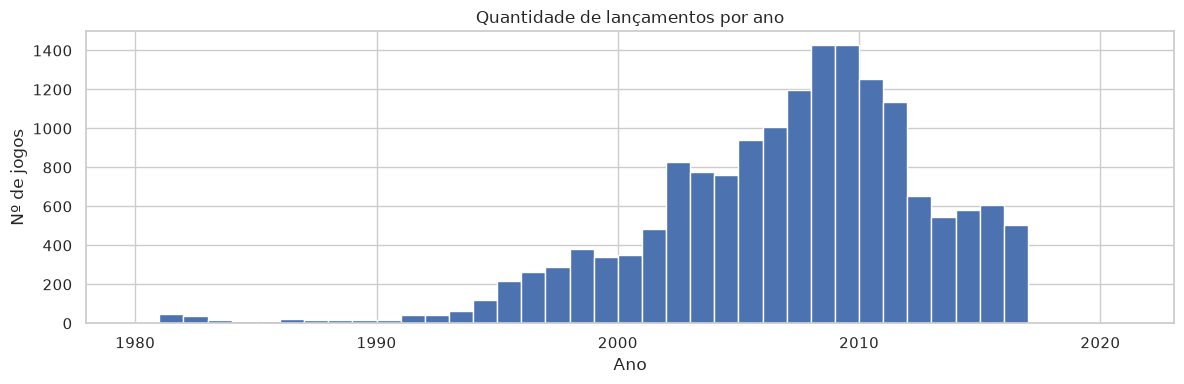

Ano mínimo: 1980 | Ano máximo: 2020


In [7]:
fig, ax = plt.subplots(figsize=(12, 4))
por_ano = df["Year_of_Release"].dropna().astype(int)
ax.hist(por_ano, bins=range(1980, 2022), color="#4C72B0", edgecolor="white")
ax.set(title="Quantidade de lançamentos por ano", xlabel="Ano", ylabel="Nº de jogos")
plt.tight_layout(); plt.show()

print("Ano mínimo:", int(por_ano.min()), "| Ano máximo:", int(por_ano.max()))


**O que este código faz**
- Cria dois histogramas lado a lado: um para `Critic_Score` (escala 0–100) e outro para
  `User_Score` (escala 0–10).
- `.dropna()` ignora as notas ausentes apenas para desenhar o gráfico.

**Para que serve:** mostrar o formato das distribuições. Escalas e formatos diferentes
são a justificativa para **padronizar com Z-score** no notebook 02.

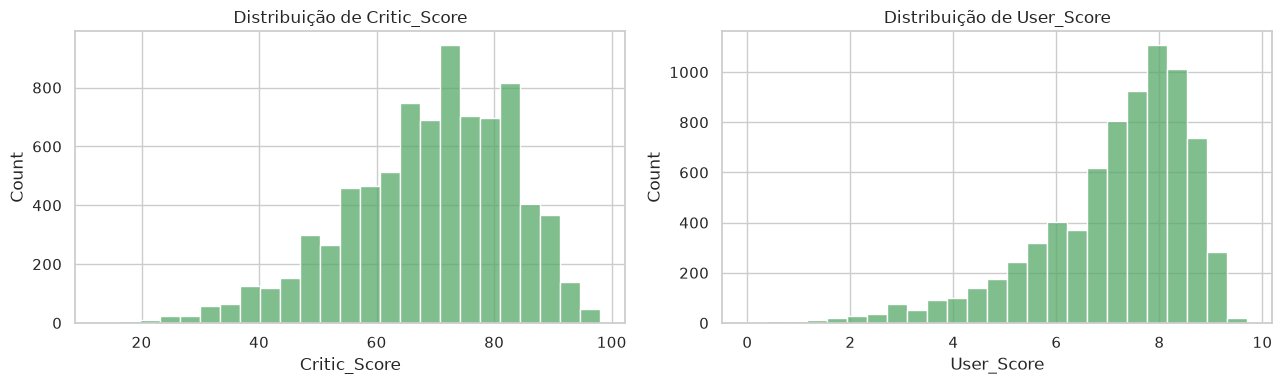

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ["Critic_Score", "User_Score"]):
    sns.histplot(df[col].dropna(), bins=25, ax=ax, color="#55A868")
    ax.set_title(f"Distribuição de {col}")
plt.tight_layout(); plt.show()


## 5. Panorama geral (Pandas: filtros e agregações)

Antes de modelar, entendemos quem domina o mercado. Essas tabelas também mostram
que a análise faz sentido: vendas e avaliação **não caminham juntas** sempre.

**O que este código faz**
- `groupby("Genre")` separa os jogos por gênero.
- `agg` calcula, para cada gênero: quantidade de jogos, soma das vendas globais,
  média da crítica e média dos usuários.
- `sort_values` ordena pelo total vendido.

**Atenção:** o `mean()` do pandas **ignora `NaN`**. Ou seja, a média de crítica usa
somente os jogos que têm nota.
**Entra:** as 16.719 linhas. **Sai:** uma tabela com uma linha por gênero (12 gêneros).
Nenhuma coluna é descartada do `df`.

In [9]:
resumo_genero = (df.groupby("Genre")
                   .agg(jogos=("Name", "size"),
                        vendas_globais=("Global_Sales", "sum"),
                        critica_media=("Critic_Score", "mean"),
                        usuario_medio=("User_Score", "mean"))
                   .sort_values("vendas_globais", ascending=False)
                   .round(2))
resumo_genero


,jogos,vendas_globais,critica_media,usuario_medio
Genre,,,,
Action,3370,1745.27,66.63,7.05
Sports,2348,1332.00,71.97,6.96
Shooter,1323,1052.94,70.18,7.04
Role-Playing,1500,934.40,72.65,7.62
Platform,888,828.08,68.06,7.30
Misc,1750,803.18,66.62,6.82
Racing,1249,728.90,67.96,7.04
Fighting,849,447.48,69.22,7.30
Simulation,874,390.42,68.62,7.13


**O que este código faz**
- Agrupa por `Platform` e calcula a quantidade de jogos e a soma das vendas.
- Ordena pelas vendas e mantém apenas as **12 primeiras** (`.head(12)`).

**Por que só 12:** existem 31 plataformas; as demais têm volume pequeno e poluiriam
o gráfico. É um recorte **apenas para visualização** — o `df` continua completo.

In [10]:
resumo_plat = (df.groupby("Platform")
                  .agg(jogos=("Name", "size"),
                       vendas_globais=("Global_Sales", "sum"))
                  .sort_values("vendas_globais", ascending=False)
                  .head(12).round(2))
resumo_plat


,jogos,vendas_globais
Platform,,
PS2,2161,1255.64
X360,1262,971.63
PS3,1331,939.43
Wii,1320,908.13
DS,2152,807.10
PS,1197,730.68
GBA,822,318.50
PS4,393,314.23
PSP,1209,294.30


**O que este código faz**
- Usa a tabela `resumo_plat` (as 12 plataformas) para desenhar um gráfico de barras horizontais.
- `sns.barplot` desenha; os `set(...)` apenas colocam título e rótulos.

**Não altera dados** — é somente visualização.

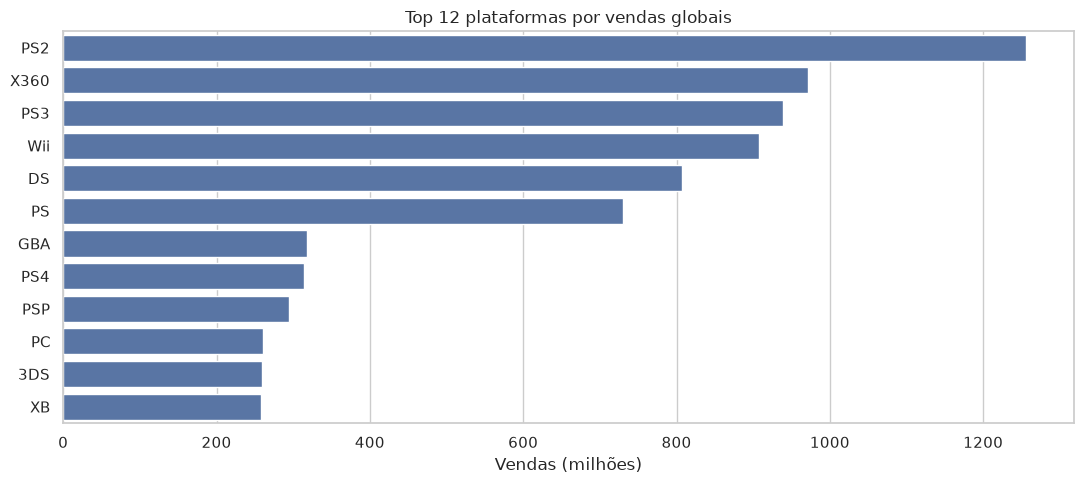

In [11]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=resumo_plat.reset_index(), x="vendas_globais", y="Platform",
            ax=ax, color="#4C72B0")
ax.set(title="Top 12 plataformas por vendas globais", xlabel="Vendas (milhões)", ylabel="")
plt.tight_layout(); plt.show()


## 6. Engenharia de atributos para a modelagem

Para responder *"quais perfis são semelhantes"* não basta usar vendas absolutas:
isso faria os grupos serem apenas "jogos grandes" vs "jogos pequenos".
Criamos então:

- `NA_share`, `EU_share`, `JP_share`, `Other_share` — **participação de cada região**
  nas vendas totais (perfil geográfico);
- `log_global_sales` — `log1p` das vendas globais, para reduzir a assimetria
  (poucos jogos vendem muito).

As notas `Critic_Score` e `User_Score` entram como atributos separados (escalas diferentes).

**O que este código faz, linha a linha**
1. Mantém apenas jogos com `Global_Sales` preenchido e **maior que zero** (não é possível
   calcular participação dividindo por zero).
2. Cria `total_regional` = soma das 4 regiões (`NA + EU + JP + Other`).
3. Remove as linhas em que esse total é zero.
4. Para cada região, cria `<REGIAO>_share` = venda da região ÷ `total_regional`.
   **Divide pelo total regional, e não por `Global_Sales`**, porque a fonte tem
   arredondamento e as 4 shares precisam somar exatamente 1.
5. Cria `log_global_sales = log1p(Global_Sales)` para comprimir a assimetria
   (Wii Sports vende 82 milhões; a mediana é 0,17 milhão).
6. Define os **7 atributos de modelagem**: `NA_share`, `EU_share`, `JP_share`,
   `Other_share`, `log_global_sales`, `Critic_Score` e `User_Score`.
7. `dropna(subset=atributos)` mantém apenas quem tem os 7 preenchidos → **7.017 linhas**.
8. Confere se as 4 shares somam 1.

**Colunas que NÃO entram na modelagem (e por quê):**
- `Global_Sales` bruto → substituído por `log_global_sales` (mesma informação, escala melhor).
- `Critic_Count` e `User_Count` → medem *quantas* pessoas avaliaram, não *quão bom* o jogo é; poderiam distorcer.
- `Year_of_Release`, `Genre`, `Platform`, `Publisher`, `Developer`, `Rating` → são categorias
  ou identificação; não entram no cálculo de distância, apenas descrevem os grupos depois.
- `Name` → identifica o jogo, não é atributo numérico.

**Entra:** 16.719 linhas × 16 colunas.
**Sai:** `base_modelagem` com **7.017 linhas × 22 colunas**
(16 originais + `total_regional` + 4 shares + `log_global_sales`).

In [12]:
df = df[df["Global_Sales"].notna() & (df["Global_Sales"] > 0)].copy()

# total regional real (o Global_Sales da fonte tem pequenas inconsistencias de arredondamento)
df["total_regional"] = df[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]].sum(axis=1)
df = df[df["total_regional"] > 0].copy()

for regiao in ["NA", "EU", "JP", "Other"]:
    df[f"{regiao}_share"] = df[f"{regiao}_Sales"] / df["total_regional"]

df["log_global_sales"] = np.log1p(df["Global_Sales"])

atributos = ["NA_share", "EU_share", "JP_share", "Other_share",
             "log_global_sales", "Critic_Score", "User_Score"]

base_modelagem = df.dropna(subset=atributos).copy()
print("Registros com todos os atributos:", len(base_modelagem))
print("\nChecagem das shares (devem somar ~1):")
print(base_modelagem[[f"{r}_share" for r in ["NA","EU","JP","Other"]]].sum(axis=1).describe().round(4))


Registros com todos os atributos: 7017

Checagem das shares (devem somar ~1):
count    7017.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0
dtype: float64


### Por que ~7.000 registros?

O enunciado sugere "algumas centenas a poucos milhares de linhas". Ao exigir notas
completas, a base cai de 16.719 para ~7.000 — o recorte natural imposto pela fonte,
justificável e suficiente para K-Means e distância Euclidiana.


## 7. Checagem de outliers (IQR) — descrever, não remover

Outliers aqui **são parte da resposta**: jogos atípicos são justamente o que queremos
encontrar. Portanto apenas registramos a quantidade, sem excluir.

**O que este código faz**
- Define a função `resumo_iqr`: calcula Q1 (25%), Q3 (75%), IQR = Q3 − Q1,
  os limites `Q1 − 1,5·IQR` e `Q3 + 1,5·IQR`, e conta quantos valores ficam fora.
- Aplica a função aos 7 atributos e monta uma tabela com mínimo, quartis, mediana, máximo e nº de outliers.

**Por que não remover os outliers:** os jogos fora do padrão são justamente a resposta
da pergunta ("quais se afastam do padrão"). Aqui apenas medimos e reportamos.

In [13]:
def resumo_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    fora = ((serie < li) | (serie > ls)).sum()
    return {"min": serie.min(), "q1": q1, "mediana": serie.median(), "q3": q3,
            "max": serie.max(), "outliers": int(fora)}

pd.DataFrame({c: resumo_iqr(base_modelagem[c]) for c in atributos}).T.round(3)


,min,q1,mediana,q3,max,outliers
NA_share,0.00,0.382,0.538,0.750,1.000,0.0
EU_share,0.00,0.123,0.273,0.391,1.000,442.0
JP_share,0.00,0.000,0.000,0.015,1.000,1469.0
Other_share,0.00,0.037,0.085,0.125,0.900,89.0
log_global_sales,0.01,0.104,0.255,0.560,4.425,430.0
Critic_Score,13.00,62.000,72.000,80.000,98.000,110.0
User_Score,0.50,6.500,7.500,8.200,9.600,273.0


## 8. Salvar a base preparada

Salvamos em `data/processed/` para o notebook 02 continuar daqui sem repetir a limpeza.

**O que este código faz**
- Define o caminho `data/processed/jogos_preparados.csv`.
- `to_csv(..., index=False)` grava a base final **sem** criar uma coluna extra de índice.
- Imprime o caminho e o formato final.

**Entra:** `base_modelagem` (7.017 × 22).
**Sai:** o arquivo `jogos_preparados.csv`, que o notebook 02 lê.
O arquivo bruto (`data/raw/`) **não é alterado**.

In [14]:
saida = RAIZ / "data" / "processed" / "jogos_preparados.csv"
base_modelagem.to_csv(saida, index=False)
print("Salvo em:", saida, "|", base_modelagem.shape)


Salvo em: /home/ivan/Ivan2.0/6°DSM/Mineracao/Porjeto_final/data/processed/jogos_preparados.csv | (7017, 22)


## 9. Conclusões desta etapa

- O dataset é adequado: 16.719 registros, 16 atributos, sem dados pessoais.
- As colunas numéricas vinham como texto e `User_Score` tinha `"tbd"` — tratado com coerção.
- As notas têm muitos ausentes por natureza da fonte; o recorte com notas completas
  gera **~7.000 registros**, coerente com o escopo do trabalho.
- Vendas absolutas foram convertidas em **participação regional + log**, para que a
  similaridade reflita *perfil de mercado*, e não apenas tamanho.
- Outliers foram **descritos**, não removidos — eles são objeto da análise.

**Próximo passo (notebook 02):** padronizar (Z-score), calcular distância Euclidiana,
aplicar K-Means com cotovelo + silhouette e perfilar os grupos.
